# Klasifikasi Dokumen Teks Menggunakan Multinomial Naive Bayes
---
## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah platform edukasi digital dan repositori artikel teknologi ingin membangun sistem pengelolaan bahasa alami (*Natural Language Processsing*) untuk mengelompokkan dokumen dan deskripsi studi kasus secara otomatis. Platform tersebut telah mengubah kumpulan dokumen teks menjadi matriks *Bag-of-Words*(fitur kata), di mana setiap dokumen direpresentasikan oleh 333 fitur kemunculan kata.
2. **Masalah**: Platform edukasi masih membaca dan mengelompokkan dokumen dan deskripsi studikasus secara manual. yang dapat membuang banyak waktu tenaga kerja dan biaya operasional.
3. **Solusi**: Membangun model *machine learning* berbasis algoritma **Naive Bayes** dengan memanfaatkan kumpulan dokumen teks yang berbentuk matriks *Bag-of-Words*.

---

## 2. Data Preprocessing

### 2.1 Import Library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2.2 Load Dataset

In [2]:
df = pd.read_csv('mldataset_v1.csv')
df.columns = df.columns.str.strip()

### 2.3 Tampikan Data Teratas dan Data Terbawah

In [3]:
df.head()

,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
0,1,1,1,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,1,0,0,1,0,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,1
2,1,1,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,1,1,1,1,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1
4,1,1,1,0,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [4]:
df.tail()

,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
595,1,1,1,1,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,6
596,1,1,1,0,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,6
597,1,1,1,1,1,1,1,0,1,0,...,0,0,0,0,0,0,0,0,0,6
598,1,1,1,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,6
599,1,1,1,1,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,6


### 2.4 Tampilkan Informasi Data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Columns: 334 entries, to to label
dtypes: int64(334)
memory usage: 1.5 MB


### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [6]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Data Kosong: {df.isnull().sum().sum()}')

print(f'Jumlah Data Duplikat: {df.duplicated().sum()}')

Dimensi Data: (600, 334)
Jumlah Data: 200400

Jumlah Data Kosong: 0
Jumlah Data Duplikat: 210


---

## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampilkan Deskripsi Data

In [7]:
df.describe()

,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
count,600.0,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,...,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.00000
mean,1.0,0.943333,0.943333,0.731667,0.660000,0.653333,0.500000,0.500000,0.480000,0.393333,...,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,3.50000
std,0.0,0.231397,0.231397,0.443462,0.474104,0.476306,0.500417,0.500417,0.500017,0.488897,...,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,1.70925
min,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.00000
25%,1.0,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.00000
50%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,0.500000,0.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.50000
75%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.00000
max,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.00000


### 3.2 Ambil 15 Frekuensi Teratas

In [8]:
top_frequency = df.drop(columns=['label']).sum().sort_values(ascending=False)
top_frequency = top_frequency.head(15)
print(top_frequency)

to           600
based        566
on           566
of           439
their        396
and          392
you          300
model        300
different    288
classify     236
an           214
types        203
predict      162
the          161
design       156
dtype: int64


### 3.3 Ambil 15 Frekuensi Terbawah

In [9]:
bottom_frequency = df.drop(columns=['label']).sum().sort_values(ascending=True)
bottom_frequency = bottom_frequency.head(15)
print(bottom_frequency)

phone         1
caller        1
call          1
style         1
fabric        1
color         1
efficiency    1
fuel          1
levels        1
dietary       1
meal          1
needs         1
plans         1
growth        1
plants        1
dtype: int64


### 3.4 Visualisasi Distribusi Data Dengan countplot

C:\Users\Hype 5 AMD X3\AppData\Local\Temp\ipykernel_13324\1846306789.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='viridis')


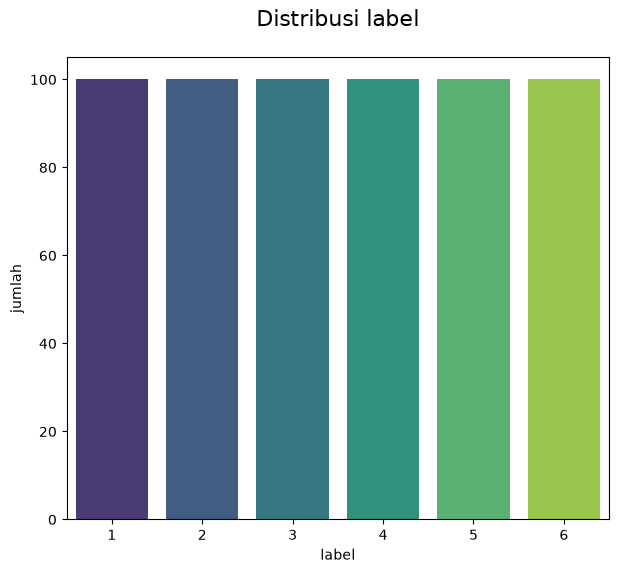

In [10]:
plt.figure(figsize=(7, 6))

sns.countplot(x='label', data=df, palette='viridis')
plt.title('Distribusi label', fontsize=16, y=1.05)
plt.xlabel('label')
plt.ylabel('jumlah')
plt.show()

**Insigt**: Keseluruhan label memiliki 100 data, yang artinya dataset tidak mengalami class imbalance sehingga akurasi dan metrik evaluasi dapat dibandingkan dengan lebih adil.

### 3.5 Visualisasi Distribusi Frekuensi Teratas Dengan Barplot

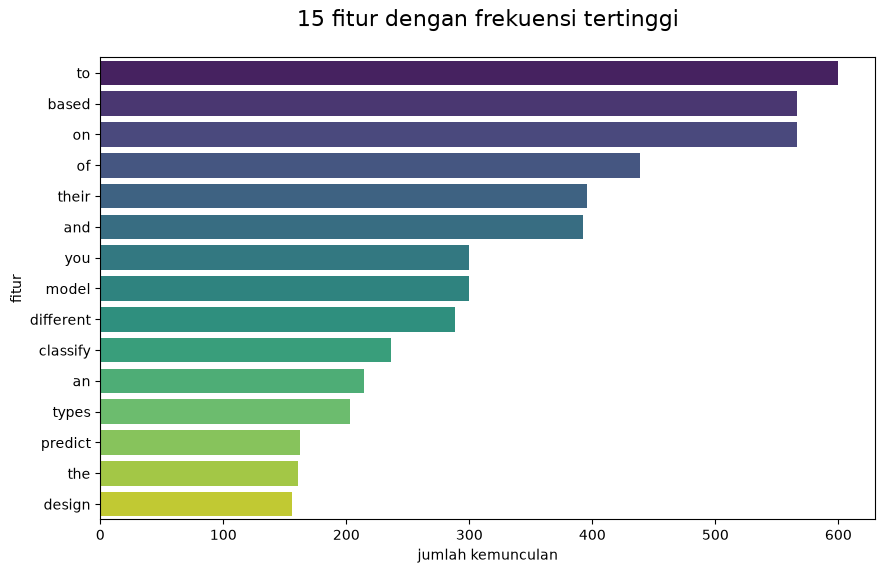

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(x=top_frequency.values, y=top_frequency.index, palette='viridis', hue=top_frequency.index)
plt.title('15 fitur dengan frekuensi tertinggi', fontsize=16, y=1.05)
plt.xlabel('jumlah kemunculan')
plt.ylabel('fitur')
plt.show()

**Insigt**: beberapa fitur seperti `to`, `based`, dan `on` paling sering muncul. Sehingga, sebagian terlalu umum untuk membedakan kelas.

### 3.6 Visualisasi Distribusi Frekuensi Terbawah dengan Barplot

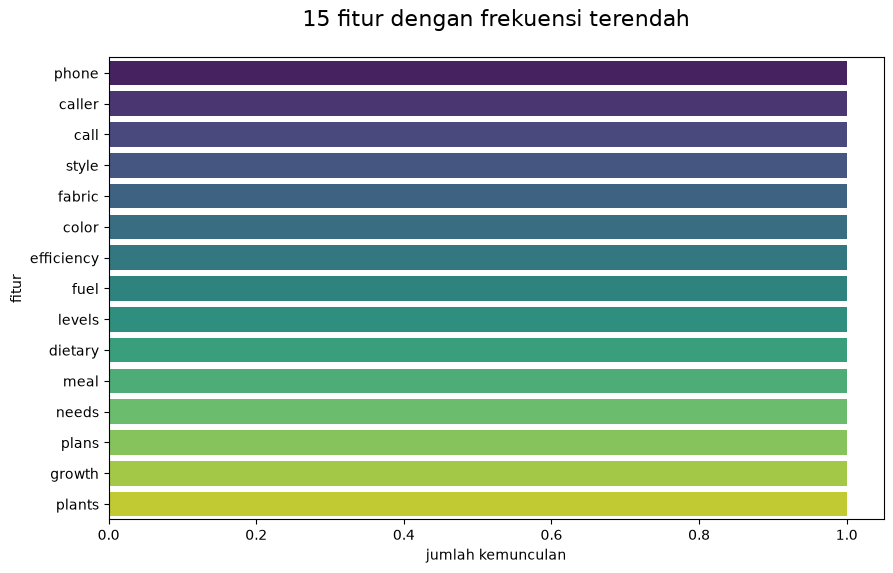

In [12]:
plt.figure(figsize=(10, 6))

sns.barplot(x=bottom_frequency.values, y=bottom_frequency.index, palette='viridis', hue=bottom_frequency.index)
plt.title('15 fitur dengan frekuensi terendah', fontsize=16, y=1.05)
plt.xlabel('jumlah kemunculan')
plt.ylabel('fitur')
plt.show()

**Insigt**: Fitur dengan frekuensi terendah dalam dataset dalam dataset, sehingga kontribusinya terhadap prediksi terbatas.

### 3.7 Visualisasi Fitur Paling Informatif Terhadap Label

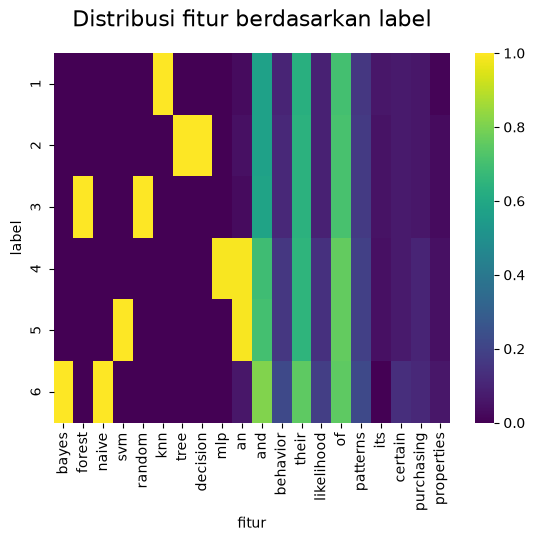

In [13]:
features_by_label = df.groupby('label').mean()
top_frequency = (features_by_label.max() - features_by_label.min()).sort_values(ascending=False).head(20).index

sns.heatmap(features_by_label[top_frequency], cmap='viridis')
plt.title('Distribusi fitur berdasarkan label', fontsize=16, y=1.05)
plt.xlabel('fitur')
plt.ylabel('label')
plt.show()

**Insigt**: Fitur seperti `bayes`, `forest`, `naive`, `smv`,  dan `knn` memiliki pola yang berbeda pada setiap label. FItur-fitur tersebut berpontensi membantu model.

---

## Conclution

1. Ekstraksi matriks kemunculan kata (Bag-of-Words) dan pengujian statistik Chi-Square ($\chi^2$) menjadi faktor kunci dalam mengenali topik dokumen. Kata kunci seperti tree, svm, knn, decision, forest, random, naive, dan bayes terbukti menjadi pembeda paling signifikan antar-kategori, sedangkan kata umum seperti to, on, dan based cenderung terdistribusi merata di seluruh dokumen.  

---

## 7. GUI

In [38]:
import tkinter as tk
from customtkinter import *

app = CTk()
app.title("Prediksi Naive Bayes Multinominal")
app.geometry("700x600")
app.config(bg="#1e1e1e")

judul = tk.Label(app, text="Prediksi Naive Bayes Mutinominal", font=("Arial", 24, "bold"), fg="white", bg="#1e1e1e")
judul.pack(pady=20)

deskripsi = tk.Label(app, text="Naive Bayes Multinominal", font=("Arial", 10), fg="white", bg="#1e1e1e")
deskripsi.pack()

entry_data = CTkTextbox(master=app, width=500, height=200, font=("Arial", 12), fg_color="white", text_color="black", corner_radius=12, border_color="gray", border_width=1)
entry_data.place(x=350, y=250, anchor="center")

# entry_data = tk.Text(app, width=50, height=10, font=("Arial", 12), fg="black", bg="white")
# entry_data.pack(pady=20)

label_hasil = CTkLabel(master=app, text="Hasil Prediksi:", font=("Arial", 12, "bold"), fg_color="white", text_color="black", corner_radius=12, width=500, height=50,)
label_hasil.place(x=350, y=400, anchor="center")

enter_data = CTkButton(master=app, text="Kirim Teks", corner_radius=32, fg_color="blue")
enter_data.place(x=350, y=474, anchor="center")

app.mainloop()

KeyboardInterrupt: 